In [2]:
# Goal: Load OpenStreetView-5M metadata via CSV files

from huggingface_hub import hf_hub_download
import pandas as pd

print("Downloading metadata CSV files...")

# Download train and test metadata
train_csv = hf_hub_download(
    repo_id="osv5m/osv5m",
    filename="train.csv",
    repo_type="dataset"
)

test_csv = hf_hub_download(
    repo_id="osv5m/osv5m",
    filename="test.csv",
    repo_type="dataset"
)

print("Download complete!")

# Load into pandas
df_train = pd.read_csv(train_csv)
df_test = pd.read_csv(test_csv)

print(f"Train samples: {len(df_train)}")
print(f"Test samples: {len(df_test)}")
print(f"\nColumns: {df_train.columns.tolist()}")

print("\nFirst 5 rows of train:")
print(df_train.head())

train.csv: reconstructing file:   0%|          |  0.00B / 2.92GB            

train.csv: downloading bytes:           |  0.00B            

test.csv: reconstructing file:   0%|          |  0.00B /  116MB            

test.csv: downloading bytes:           |  0.00B            

Download complete!


/var/folders/ct/chbp26vx6hbc26zt3mtv_9p40000gn/T/ipykernel_28760/412397938.py:24: DtypeWarning: Columns (11: sub-region, 27: unique_sub-region) have mixed types. Specify dtype option on import or set low_memory=False.
  df_train = pd.read_csv(train_csv)


Train samples: 4894684
Test samples: 210122

Columns: ['id', 'latitude', 'longitude', 'thumb_original_url', 'country', 'sequence', 'captured_at', 'lon_bin', 'lat_bin', 'cell', 'region', 'sub-region', 'city', 'land_cover', 'road_index', 'drive_side', 'climate', 'soil', 'dist_sea', 'quadtree_10_5000', 'quadtree_10_25000', 'quadtree_10_1000', 'quadtree_10_50000', 'quadtree_10_12500', 'quadtree_10_500', 'quadtree_10_2500', 'unique_region', 'unique_sub-region', 'unique_city', 'unique_country', 'creator_username', 'creator_id']

First 5 rows of train:
                 id   latitude   longitude  \
0  3859149887465501 -43.804769 -176.614093   
1   574181207305439 -43.796611 -176.660483   
2   333574322129026 -43.818092 -176.578383   
3   636305258168031 -44.052910 -176.633065   
4   166741299029322 -43.748077 -176.329626   

                                  thumb_original_url country  \
0  https://scontent-cdg4-1.xx.fbcdn.net/m1/v/t6/A...      NZ   
1  https://scontent-cdg4-1.xx.fbcdn.net/m1/

In [3]:
# Check how many images we have for our 8 selected countries

selected_countries = [
    "JP",  # Japan
    "FR",  # France
    "BR",  # Brazil
    "AU",  # Australia
    "IN",  # India
    "ZA",  # South Africa
    "US",  # United States
    "TH"   # Thailand
]

print("=== Train set ===")
train_counts = df_train[df_train["country"].isin(selected_countries)]["country"].value_counts()
print(train_counts)

print("\n=== Test set ===")
test_counts = df_test[df_test["country"].isin(selected_countries)]["country"].value_counts()
print(test_counts)

print("\nTotal for selected countries:")
print(f"Train: {train_counts.sum()}")
print(f"Test: {test_counts.sum()}")

=== Train set ===
country
US    1218664
FR     242074
JP     209205
AU     162138
BR     140599
TH      74763
ZA      53443
IN      50604
Name: count, dtype: int64

=== Test set ===
country
US    23875
AU    11052
BR    10425
IN     6525
ZA     2969
TH     2682
JP     2128
FR     2047
Name: count, dtype: int64

Total for selected countries:
Train: 2151490
Test: 61703


In [4]:
# Sample 400 images per country from train set

sampled_dfs = []

for country in selected_countries:
    country_df = df_train[df_train["country"] == country]
    # Sample 400 (or all if less than 400)
    n_sample = min(400, len(country_df))
    sampled = country_df.sample(n=n_sample, random_state=42)
    sampled_dfs.append(sampled)
    print(f"{country}: sampled {n_sample} images")

# Combine all samples
df_sampled = pd.concat(sampled_dfs, ignore_index=True)

print(f"\nTotal sampled images: {len(df_sampled)}")
print(df_sampled["country"].value_counts())

# Save the sampled metadata
df_sampled.to_csv("../data/sampled_metadata.csv", index=False)
print("\nSaved to data/sampled_metadata.csv")

JP: sampled 400 images
FR: sampled 400 images
BR: sampled 400 images
AU: sampled 400 images
IN: sampled 400 images
ZA: sampled 400 images
US: sampled 400 images
TH: sampled 400 images

Total sampled images: 3200
country
JP    400
FR    400
BR    400
AU    400
IN    400
ZA    400
US    400
TH    400
Name: count, dtype: int64

Saved to data/sampled_metadata.csv


In [5]:
# Quick inspection of the sampled data

print("Shape:", df_sampled.shape)
print("\nColumns:")
print(df_sampled.columns.tolist())

print("\nCountry distribution:")
print(df_sampled["country"].value_counts())

print("\nSample of latitude / longitude:")
print(df_sampled[["country", "latitude", "longitude"]].head(10))

print("\nMissing values:")
print(df_sampled.isnull().sum())

Shape: (3200, 32)

Columns:
['id', 'latitude', 'longitude', 'thumb_original_url', 'country', 'sequence', 'captured_at', 'lon_bin', 'lat_bin', 'cell', 'region', 'sub-region', 'city', 'land_cover', 'road_index', 'drive_side', 'climate', 'soil', 'dist_sea', 'quadtree_10_5000', 'quadtree_10_25000', 'quadtree_10_1000', 'quadtree_10_50000', 'quadtree_10_12500', 'quadtree_10_500', 'quadtree_10_2500', 'unique_region', 'unique_sub-region', 'unique_city', 'unique_country', 'creator_username', 'creator_id']

Country distribution:
country
JP    400
FR    400
BR    400
AU    400
IN    400
ZA    400
US    400
TH    400
Name: count, dtype: int64

Sample of latitude / longitude:
  country   latitude   longitude
0      JP  33.394352  129.986341
1      JP  34.782217  135.486225
2      JP  32.601296  130.436719
3      JP  34.839881  136.360548
4      JP  36.050750  136.233975
5      JP  37.905391  139.007194
6      JP  38.923973  141.133564
7      JP  35.143112  139.877799
8      JP  36.366451  139.47343

Matplotlib is building the font cache; this may take a moment.


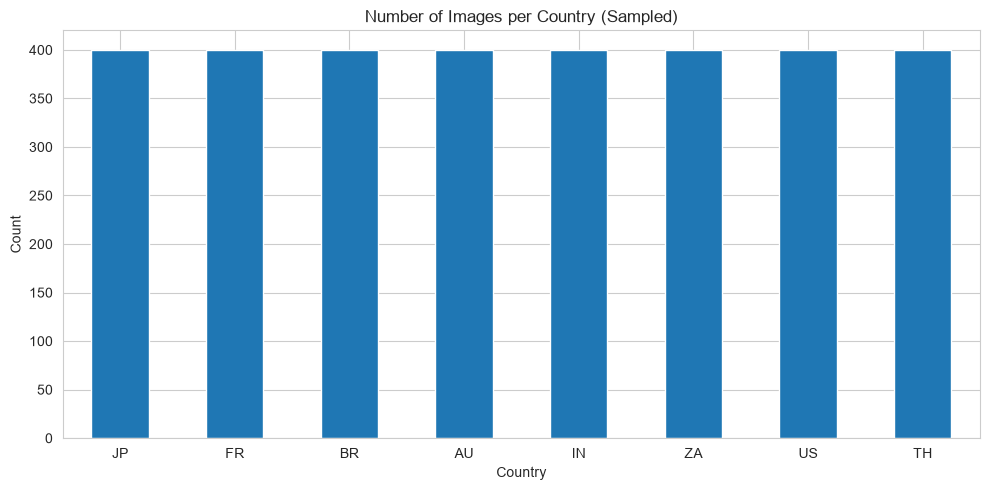

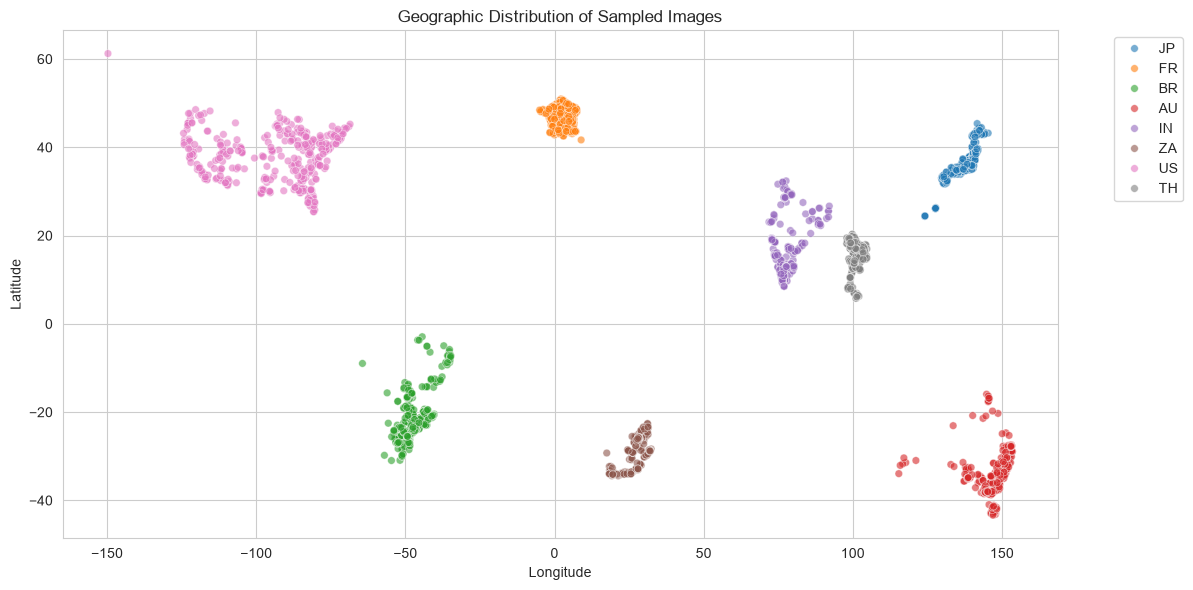

EDA visualizations completed.


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# 1. Country distribution bar chart
plt.figure(figsize=(10, 5))
df_sampled["country"].value_counts().plot(kind="bar")
plt.title("Number of Images per Country (Sampled)")
plt.xlabel("Country")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 2. Geographic scatter plot (latitude vs longitude)
plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=df_sampled,
    x="longitude",
    y="latitude",
    hue="country",
    alpha=0.6,
    s=30
)
plt.title("Geographic Distribution of Sampled Images")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

print("EDA visualizations completed.")

Saved country_distribution.png
Saved geographic_distribution.png

Plots saved to reports/ folder.


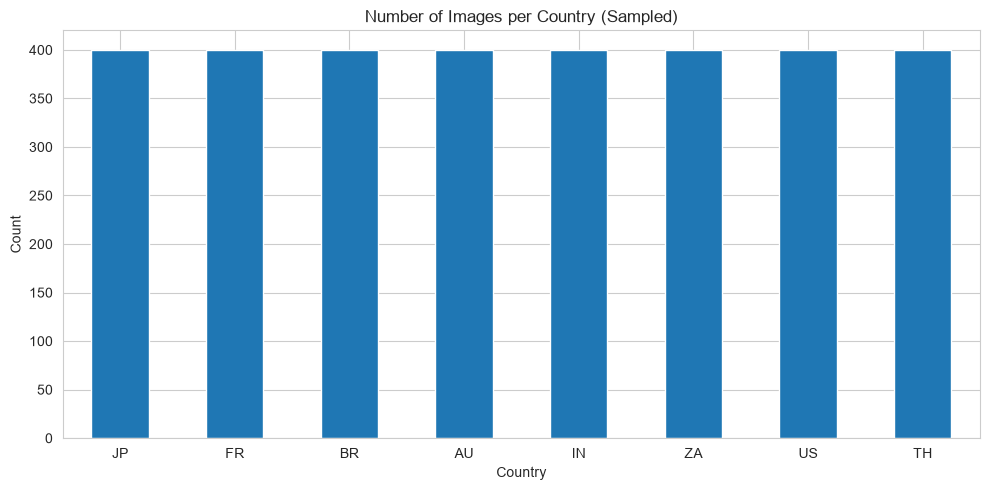

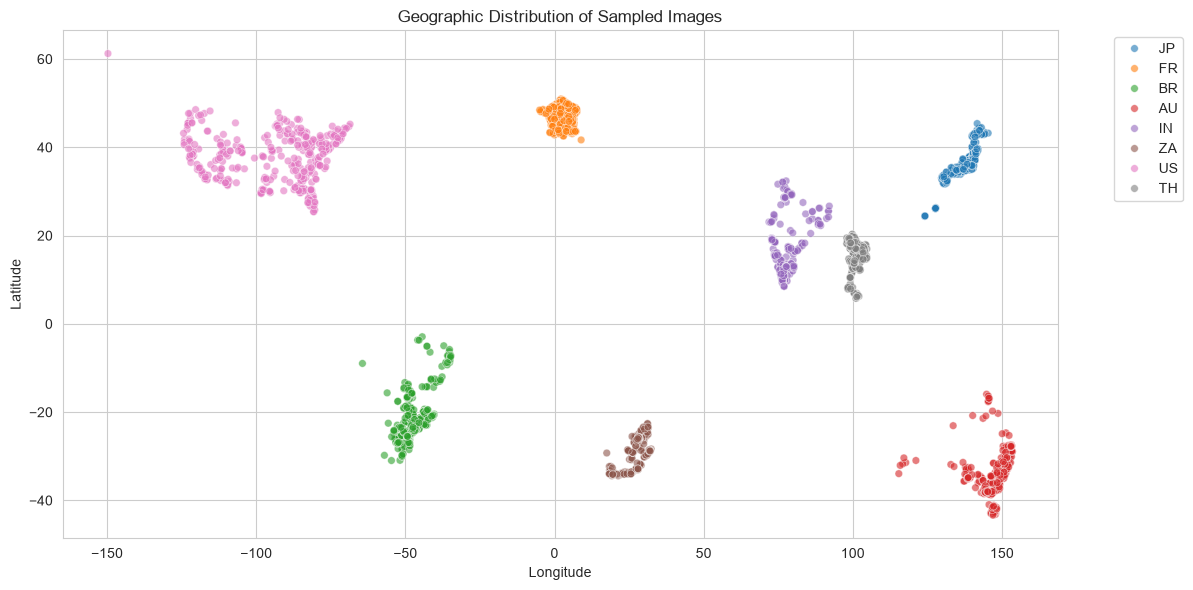

In [7]:
import os

# Create reports folder if it doesn't exist
os.makedirs("../reports", exist_ok=True)

# Re-create and save the plots
fig1, ax1 = plt.subplots(figsize=(10, 5))
df_sampled["country"].value_counts().plot(kind="bar", ax=ax1)
ax1.set_title("Number of Images per Country (Sampled)")
ax1.set_xlabel("Country")
ax1.set_ylabel("Count")
plt.xticks(rotation=0)
plt.tight_layout()
fig1.savefig("../reports/country_distribution.png", dpi=150)
print("Saved country_distribution.png")

fig2, ax2 = plt.subplots(figsize=(12, 6))
sns.scatterplot(
    data=df_sampled,
    x="longitude",
    y="latitude",
    hue="country",
    alpha=0.6,
    s=30,
    ax=ax2
)
ax2.set_title("Geographic Distribution of Sampled Images")
ax2.set_xlabel("Longitude")
ax2.set_ylabel("Latitude")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
fig2.savefig("../reports/geographic_distribution.png", dpi=150)
print("Saved geographic_distribution.png")

print("\nPlots saved to reports/ folder.")